# 02 — Q2a: Which genes respond to PSCA, direct RT and indirect RT, in which cell type?

Pseudobulk DESeq2 (pydeseq2) on **summed raw counts**, one observation per sample, for every
cell group with enough usable samples (>= 10 cells). Eleven fits per cell group:

| contrast | samples | design | coefficient |
|---|---|---|---|
| `PSCA_nonRT` | CyPSCA + CyT72, both sites | `~ site + car` | PSCA vs TAG72 |
| `PSCA_RT` | RTCyPSCA + RTCyT72, both sites | `~ site + car` | PSCA vs TAG72 |
| `directRT_PSCA` / `_TAG72` | Tu1 of RT + non-RT arm, one background | `~ rt` | RT vs no RT |
| `indirectRT_PSCA` / `_TAG72` | Tu2 of RT + non-RT arm | `~ rt` | RT vs no RT |
| `CARxRT` | all treated | `~ site + car + rt + car:rt` | RT effect in PSCA − RT effect in TAG72 |
| `DiD_PSCA` / `_TAG72` | mice with both sites, one background | `~ mouse + site + did` | (Tu1 − Tu2)_RT − (Tu1 − Tu2)_non-RT |
| `TxNoTx` | CyPSCA + CyT72 + NoTx | `~ site + tx` | pipeline check only |

### Multiple testing
Genome-wide `padj` is DESeq2's own. For the **pre-specified panels** — chemokine ligands,
chemokine receptors, MHC, cytotoxic, exhaustion and checkpoint genes — `panel_padj` is a separate
BH correction **within each panel**, per cell group and contrast. Ligands and receptors are
corrected separately. Panel genes bypass the genome-wide expression filter (they only need
reads in >= 2 samples), so a sparse but pre-specified chemokine is still tested; its `baseMean`
is reported so a low-count result can be read as such.

### Reproducibility rule
* **PSCA** — same sign in `PSCA_nonRT` and `PSCA_RT`, nominal p < 0.05 in both, panel_padj < 0.05
  in at least one.
* **direct / indirect RT** — the same rule across the two CAR backgrounds.

Then **leave-one-mouse-out** on the sample-level log CPM: does the sign survive dropping each
sample in turn?

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, time, logging
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
logging.disable(logging.WARNING)

pd.set_option("display.width", 280); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 400)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/mhc_cytotox"; FIG = OUT/"figures"
MIN_CELLS, N_CPUS = 10, 8
INF = DefaultInference(n_cpus=N_CPUS)
RECOMPUTE = False                 # True refits everything even if de_all.parquet exists

PB = pd.read_parquet(OUT/"pseudobulk_counts.parquet")
PBM = pd.read_csv(OUT/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
CAT = json.load(open(OUT/"programs.json")); PROGRAMS, AXES = CAT["programs"], CAT["axes"]

GROUPS = ["Cancer_cell", "IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "Classical_Mono",
          "Nonclassical_Mono", "N1_like_Neu", "N2_like_Neu", "cDC", "NK", "CD8_T", "cytotoxic_lymph",
          "SPP1_TAM", "Fibroblast", "Endothelial"]

PANELS = {
    "chemokine_ligand":   sorted({g for v in AXES.values() for g in v["ligands"]}),
    "chemokine_receptor": sorted({g for v in AXES.values() for g in v["receptors"]}),
    "MHC":         sorted(set(PROGRAMS["MHC_I_machinery"]["genes"]) | set(PROGRAMS["MHC_II_core"]["genes"])),
    "cytotoxic":   sorted(set(PROGRAMS["cyto_effector"]["genes"])),
    "exhaustion":  sorted(set(PROGRAMS["exh_inhibitory_receptors"]["genes"]) | set(PROGRAMS["exh_TFs"]["genes"])
                          | set(PROGRAMS["exh_progenitor"]["genes"]) | set(PROGRAMS["exh_terminal"]["genes"])),
    "checkpoint":  sorted(set(PROGRAMS["checkpoint_ligands"]["genes"])),
    "IFN":         sorted(set(PROGRAMS["ISG_core"]["genes"])),
}
PANEL_GENES = sorted({g for v in PANELS.values() for g in v})
print({k: len(v) for k, v in PANELS.items()})

{'chemokine_ligand': 18, 'chemokine_receptor': 9, 'MHC': 21, 'cytotoxic': 11, 'exhaustion': 22, 'checkpoint': 7, 'IFN': 10}


## 2. The fitting engine

In [2]:
def sample_meta(keys):
    d = PBM.loc[keys]
    m = pd.DataFrame(index=keys)
    m["site"] = pd.Categorical(np.where(d.site == 1, "Tu1", "Tu2"), ["Tu2", "Tu1"])
    m["car"] = pd.Categorical(d.cart.values, ["TAG72", "PSCA"])
    m["rt"] = pd.Categorical(np.where(d.RT, "RT", "noRT"), ["noRT", "RT"])
    m["tx"] = pd.Categorical(np.where(d.arm == "NoTx", "no", "yes"), ["no", "yes"])
    m["mouse"] = d.mouse.values
    m["did"] = pd.Categorical(np.where((d.site == 1) & d.RT, "yes", "no"), ["no", "yes"])
    m["arm"], m["sample"] = d.arm.values, d["sample"].values
    return m


def select(group, arms=None, site=None, paired=False):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    if arms: d = d[d.arm.isin(arms)]
    if site: d = d[d.site == site]
    if paired:
        both = d.groupby("mouse").site.nunique(); d = d[d.mouse.isin(both[both == 2].index)]
    return list(d.index)


CONTRASTS = {   # name: (arms, site, paired, design, coefficient, (factor, level) to check sides)
    "PSCA_nonRT":      (["CyPSCA", "CyT72"], None, False, "~ site + car", ["car", "PSCA", "TAG72"], "car"),
    "PSCA_RT":         (["RTCyPSCA", "RTCyT72"], None, False, "~ site + car", ["car", "PSCA", "TAG72"], "car"),
    "directRT_PSCA":   (["RTCyPSCA", "CyPSCA"], 1, False, "~ rt", ["rt", "RT", "noRT"], "rt"),
    "directRT_TAG72":  (["RTCyT72", "CyT72"], 1, False, "~ rt", ["rt", "RT", "noRT"], "rt"),
    "indirectRT_PSCA": (["RTCyPSCA", "CyPSCA"], 2, False, "~ rt", ["rt", "RT", "noRT"], "rt"),
    "indirectRT_TAG72": (["RTCyT72", "CyT72"], 2, False, "~ rt", ["rt", "RT", "noRT"], "rt"),
    "CARxRT":          (["CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"], None, False,
                        "~ site + car + rt + car:rt", "interaction", "car"),
    "DiD_PSCA":        (["RTCyPSCA", "CyPSCA"], None, True, "~ mouse + site + did", ["did", "yes", "no"], "did"),
    "DiD_TAG72":       (["RTCyT72", "CyT72"], None, True, "~ mouse + site + did", ["did", "yes", "no"], "did"),
    "TxNoTx":          (["CyPSCA", "CyT72", "NoTx"], None, False, "~ site + tx", ["tx", "yes", "no"], "tx"),
}


def fit(group, cname):
    arms, site, paired, design, coef, fac = CONTRASTS[cname]
    keys = select(group, arms, site, paired)
    if len(keys) < 4: return None, f"{len(keys)} samples"
    meta = sample_meta(keys)
    for f_ in ["car", "rt", "tx", "did"]:
        meta[f_] = meta[f_].cat.remove_unused_categories()
    if meta[fac].nunique() < 2 or meta[fac].value_counts().min() < 2:
        return None, f"one side < 2 ({meta[fac].value_counts().to_dict()})"
    X = PB.loc[keys]
    keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | \
           (X.columns.isin(PANEL_GENES) & ((X > 0).sum(0) >= 2))
    X = X.loc[:, keep]
    try:
        dds = DeseqDataSet(counts=X, metadata=meta, design=design, inference=INF, quiet=True)
        dds.deseq2()
        if coef == "interaction":
            cols = list(dds.obsm["design_matrix"].columns)
            ic = [c for c in cols if ":" in c]
            assert len(ic) == 1 and "PSCA" in ic[0] and "[T.RT]" in ic[0], cols
            v = np.zeros(len(cols)); v[cols.index(ic[0])] = 1
            st = DeseqStats(dds, contrast=v, inference=INF, quiet=True)
        else:
            st = DeseqStats(dds, contrast=coef, inference=INF, quiet=True)
        st.summary()
    except Exception as e:
        return None, f"FAILED {type(e).__name__}: {str(e)[:80]}"
    r = st.results_df.copy()
    sides = meta[fac].value_counts()
    r["n"] = "v".join(str(sides.get(k, 0)) for k in (["yes", "no"] if fac in ("tx", "did") else
                                                    ["PSCA", "TAG72"] if fac == "car" else ["RT", "noRT"]))
    return r, "ok"


DE_FILE = OUT/"de_all.parquet"
if DE_FILE.exists() and not RECOMPUTE:
    DE = pd.read_parquet(DE_FILE); LOG = pd.read_csv(OUT/"de_fit_log.csv")
    print(f"loaded {DE_FILE.name}: {len(DE):,} rows")
else:
    res, log = [], []
    t0 = time.time()
    for g in GROUPS:
        for cname in CONTRASTS:
            r, msg = fit(g, cname)
            log.append(dict(group=g, contrast=cname, status=msg,
                            n=r["n"].iloc[0] if r is not None else "",
                            n_padj05=int((r.padj < 0.05).sum()) if r is not None else np.nan))
            if r is not None:
                res.append(r.assign(group=g, contrast=cname).reset_index(names="gene"))
        print(f"  {g:<20s} done  {time.time()-t0:5.0f}s", flush=True)
    DE = pd.concat(res, ignore_index=True); LOG = pd.DataFrame(log)
    DE.to_parquet(DE_FILE); LOG.to_csv(OUT/"de_fit_log.csv", index=False)

print("\ngenome-wide genes at padj < 0.05, per cell group x contrast (blank = not fittable)")
print(LOG.pivot(index="group", columns="contrast", values="n_padj05").reindex(GROUPS)[list(CONTRASTS)]
        .to_string(float_format=lambda x: f"{x:.0f}"))
print("\nsamples per side (A v B):")
print(LOG.pivot(index="group", columns="contrast", values="n").reindex(GROUPS)[list(CONTRASTS)].to_string())

loaded de_all.parquet: 957,678 rows

genome-wide genes at padj < 0.05, per cell group x contrast (blank = not fittable)
contrast            PSCA_nonRT  PSCA_RT  directRT_PSCA  directRT_TAG72  indirectRT_PSCA  indirectRT_TAG72  CARxRT  DiD_PSCA  DiD_TAG72  TxNoTx
group                                                                                                                                         
Cancer_cell                569        6              2               0                0                 0       0         0          0    1587
IFN_stimulated_Mac        1489      729             32               0                0                 6       0         4          1    1660
M2_like_Mac                776      241             36               0                1                 4       2         7          0    4574
Intermediate_Mac           758      533             17               0                0                12       0         3          0    1758
Classical_Mono        

## 3. Positive controls — does the machinery see what is known to be there?

* treated vs NoTx in macrophages: MHC and ISGs should be up;
* PSCA vs TAG72 in IFN-stimulated macrophages / SPP1-TAMs: `Gbp2`, `Irf1`, `Stat1` should be
  up (`spp1Analysis/10`: 342 / 192 genes at padj < 0.05 in SPP1-TAMs).

In [3]:
def show(group, cname, genes_):
    d = DE[(DE.group == group) & (DE.contrast == cname)].set_index("gene").reindex(genes_)
    return d[["baseMean", "log2FoldChange", "pvalue", "padj"]]


for g_, c_, gl in [("IFN_stimulated_Mac", "TxNoTx", ["H2-K1", "B2m", "H2-Ab1", "Cd74", "Stat1", "Irf1"]),
                   ("IFN_stimulated_Mac", "PSCA_nonRT", ["Gbp2", "Gbp5", "Irf1", "Stat1", "Cxcl9", "Cxcl10"]),
                   ("SPP1_TAM", "PSCA_nonRT", ["Gbp2", "Gbp5", "Irf1", "Stat1", "Cxcl9", "Cxcl10"]),
                   ("SPP1_TAM", "PSCA_RT", ["Gbp2", "Gbp5", "Irf1", "Stat1", "Cxcl9", "Cxcl10"])]:
    print(f"\n--- {g_} | {c_} ---")
    print(show(g_, c_, gl).round(4).to_string())


--- IFN_stimulated_Mac | TxNoTx ---
         baseMean  log2FoldChange  pvalue    padj
gene                                             
H2-K1   2411.3227          1.1902  0.0000  0.0000
B2m     3609.2897          0.8928  0.0000  0.0000
H2-Ab1  3417.0177          0.5582  0.0049  0.0277
Cd74    7040.2272          0.4514  0.0029  0.0178
Stat1    653.0608          2.0205  0.0000  0.0000
Irf1     356.2384          1.7572  0.0015  0.0105

--- IFN_stimulated_Mac | PSCA_nonRT ---
         baseMean  log2FoldChange  pvalue    padj
gene                                             
Gbp2    2536.3219          3.0684     0.0  0.0000
Gbp5    1064.8450          2.0402     0.0  0.0000
Irf1    1632.9836          2.4493     0.0  0.0000
Stat1   3048.4318          1.0646     0.0  0.0000
Cxcl9   1673.3608          3.1024     0.0  0.0000
Cxcl10  4233.6093          0.8370     0.0  0.0001

--- SPP1_TAM | PSCA_nonRT ---


         baseMean  log2FoldChange  pvalue    padj
gene                                             
Gbp2    1682.2107          2.6614  0.0000  0.0000
Gbp5     567.1041          1.9114  0.0000  0.0000
Irf1    1148.5431          2.3996  0.0000  0.0000
Stat1   2418.0518          0.9057  0.0003  0.0142
Cxcl9    627.4015          2.4272  0.0020  0.0571
Cxcl10  2517.0875          1.4866  0.0000  0.0006

--- SPP1_TAM | PSCA_RT ---


         baseMean  log2FoldChange  pvalue    padj
gene                                             
Gbp2    1981.3147          2.7205  0.0000  0.0000
Gbp5     612.4323          1.9908  0.0000  0.0000
Irf1    1256.1818          2.0004  0.0000  0.0000
Stat1   2743.5030          1.1814  0.0000  0.0000
Cxcl9    593.7140          2.3789  0.0000  0.0016
Cxcl10  3002.8405          1.3498  0.0035  0.1302


## 4. Panel genes — within-panel BH, reproducibility, leave-one-mouse-out

In [4]:
role_of = {}
for k, v in PANELS.items():
    for g in v: role_of.setdefault(g, k)
P = DE[DE.gene.isin(PANEL_GENES)].copy()
P["panel"] = P.gene.map(role_of)
P["panel_padj"] = np.nan
for (g_, c_, pn), d in P.groupby(["group", "contrast", "panel"]):
    ok = d.pvalue.notna()
    if ok.sum():
        P.loc[d.index[ok], "panel_padj"] = multipletests(d.pvalue[ok], method="fdr_bh")[1]
P.to_csv(OUT/"de_panel_genes.csv", index=False)

L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)


def loo_sign(group, cname, gene):
    """Sign of the A-minus-B log CPM difference with each sample dropped; site-centred where the
    design has a site term. Returns 'k/n' samples whose removal flips the sign."""
    arms, site, paired, design, coef, fac = CONTRASTS[cname]
    if fac not in ("car", "rt"): return ""
    keys = select(group, arms, site, paired)
    m = sample_meta(keys); y = L.loc[keys, gene]
    if "site" in design: y = y - y.groupby(m.site.values).transform("mean")
    a_lab = "PSCA" if fac == "car" else "RT"
    a = (m[fac] == a_lab).values
    base = np.sign(y[a].mean() - y[~a].mean())
    flips = 0
    for i in range(len(y)):
        keep = np.ones(len(y), bool); keep[i] = False
        if (a & keep).sum() < 1 or (~a & keep).sum() < 1: continue
        flips += np.sign(y[a & keep].mean() - y[~a & keep].mean()) != base
    return f"{flips}/{len(y)}"


REP = {"PSCA": ("PSCA_nonRT", "PSCA_RT"), "direct RT": ("directRT_PSCA", "directRT_TAG72"),
       "indirect RT": ("indirectRT_PSCA", "indirectRT_TAG72")}
rows = []
for (g_, gene), d in P.groupby(["group", "gene"]):
    d = d.set_index("contrast")
    for name, (c1, c2) in REP.items():
        if c1 not in d.index or c2 not in d.index: continue
        a, b = d.loc[c1], d.loc[c2]
        agree = np.sign(a.log2FoldChange) == np.sign(b.log2FoldChange)
        rep = bool(agree and a.pvalue < 0.05 and b.pvalue < 0.05 and
                   min(a.panel_padj, b.panel_padj) < 0.05)
        rows.append(dict(group=g_, gene=gene, panel=role_of[gene], effect=name,
                         lfc_1=a.log2FoldChange, p_1=a.pvalue, q_1=a.panel_padj,
                         lfc_2=b.log2FoldChange, p_2=b.pvalue, q_2=b.panel_padj,
                         baseMean=(a.baseMean + b.baseMean) / 2, sign_agree=bool(agree), replicated=rep))
R = pd.DataFrame(rows)
R["loo_flips"] = ""
for i, r in R[R.replicated].iterrows():
    c1, c2 = REP[r.effect]
    R.loc[i, "loo_flips"] = f"{loo_sign(r.group, c1, r.gene)} | {loo_sign(r.group, c2, r.gene)}"
R.to_csv(OUT/"de_panel_replication.csv", index=False)

for name in REP:
    d = R[(R.effect == name) & R.replicated].sort_values(["panel", "group"])
    print(f"\n=== {name.upper()} — panel genes REPLICATED in both "
          f"{'RT strata' if name == 'PSCA' else 'CAR backgrounds'} ({len(d)}) ===")
    print(d[["panel", "group", "gene", "baseMean", "lfc_1", "q_1", "lfc_2", "q_2", "loo_flips"]]
          .round(3).to_string(index=False) if len(d) else "    none")

# interaction and DiD: single fits, panel_padj < 0.05
for cname in ["CARxRT", "DiD_PSCA", "DiD_TAG72"]:
    d = P[(P.contrast == cname) & (P.panel_padj < 0.05)].sort_values(["panel", "group"])
    print(f"\n=== {cname} — panel genes at panel_padj < 0.05 ({len(d)}) ===")
    print(d[["panel", "group", "gene", "baseMean", "log2FoldChange", "pvalue", "panel_padj", "n"]]
          .round(4).to_string(index=False) if len(d) else "    none")


=== PSCA — panel genes REPLICATED in both RT strata (227) ===
             panel              group     gene  baseMean  lfc_1   q_1  lfc_2   q_2   loo_flips
               IFN        Cancer_cell     Gbp2    76.646  3.772 0.000  4.058 0.000 0/11 | 0/12
               IFN        Cancer_cell     Irf1    35.911  0.997 0.081  2.267 0.000 0/11 | 0/12
               IFN     Classical_Mono     Gbp2  6046.983  3.164 0.000  3.114 0.000 0/11 | 0/12
               IFN     Classical_Mono     Gbp5  2553.687  2.036 0.000  2.290 0.000 0/11 | 0/12
               IFN     Classical_Mono    Ifit1  3051.496  0.396 0.043  0.507 0.009 1/11 | 0/12
               IFN     Classical_Mono     Irf1  2862.800  2.507 0.000  1.973 0.000 0/11 | 0/12
               IFN     Classical_Mono    Oasl1  3199.283  1.027 0.000  0.502 0.017 0/11 | 0/12
               IFN     Classical_Mono    Stat1  6211.032  1.106 0.000  1.560 0.000 0/11 | 0/12
               IFN        Endothelial     Gbp2   106.389  2.654 0.001  3.739 0.000

## 5. Chemokines — ligands and receptors, every contrast

The chemokine panel on its own: every ligand in its plausible source groups and every receptor
in its plausible target groups, log2FC with `panel_padj` stars (* < 0.05, + < 0.10).

In [5]:
SRC_GROUPS = ["IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "Classical_Mono", "cDC",
              "N1_like_Neu", "N2_like_Neu", "Cancer_cell", "NK", "CD8_T", "Fibroblast", "Endothelial"]
CMAIN = ["PSCA_nonRT", "PSCA_RT", "directRT_PSCA", "directRT_TAG72", "indirectRT_PSCA",
         "indirectRT_TAG72", "CARxRT", "DiD_PSCA", "DiD_TAG72"]


def star(q):
    return "*" if q < 0.05 else "+" if q < 0.10 else ""


for role in ["chemokine_ligand", "chemokine_receptor"]:
    d = P[(P.panel == role) & P.group.isin(SRC_GROUPS) & P.contrast.isin(CMAIN)].copy()
    d = d[d.baseMean >= 5]
    d["cell"] = d.log2FoldChange.round(1).astype(str) + d.panel_padj.map(lambda q: star(q) if pd.notna(q) else "")
    t = d.pivot_table(index=["gene", "group"], columns="contrast", values="cell", aggfunc="first")[CMAIN]
    hit = d.groupby(["gene", "group"]).panel_padj.min() < 0.10
    print(f"\n=== {role} — rows with panel_padj < 0.10 in at least one contrast (baseMean >= 5) ===")
    print(t[hit.reindex(t.index).fillna(False).values].to_string())


=== chemokine_ligand — rows with panel_padj < 0.10 in at least one contrast (baseMean >= 5) ===
contrast                  PSCA_nonRT PSCA_RT directRT_PSCA directRT_TAG72 indirectRT_PSCA indirectRT_TAG72 CARxRT DiD_PSCA DiD_TAG72
gene   group                                                                                                                        
Ccl12  Cancer_cell              1.3*     0.5           0.9            1.4            -0.3              0.6   -0.8      1.3       0.9
       Classical_Mono           1.0*     0.6           0.4            0.5            -0.3              0.6   -0.4      0.1       0.0
       IFN_stimulated_Mac       1.2*    1.4*           0.5           -0.1            -0.5             -0.3    0.2      0.6       0.1
       Intermediate_Mac         1.6*    2.1*           1.6            0.2             0.0              0.4    0.6      1.0      -0.2
       M2_like_Mac              1.0*     0.7           0.6            0.5            -0.2              0.

## 6. Figures — focused heatmaps

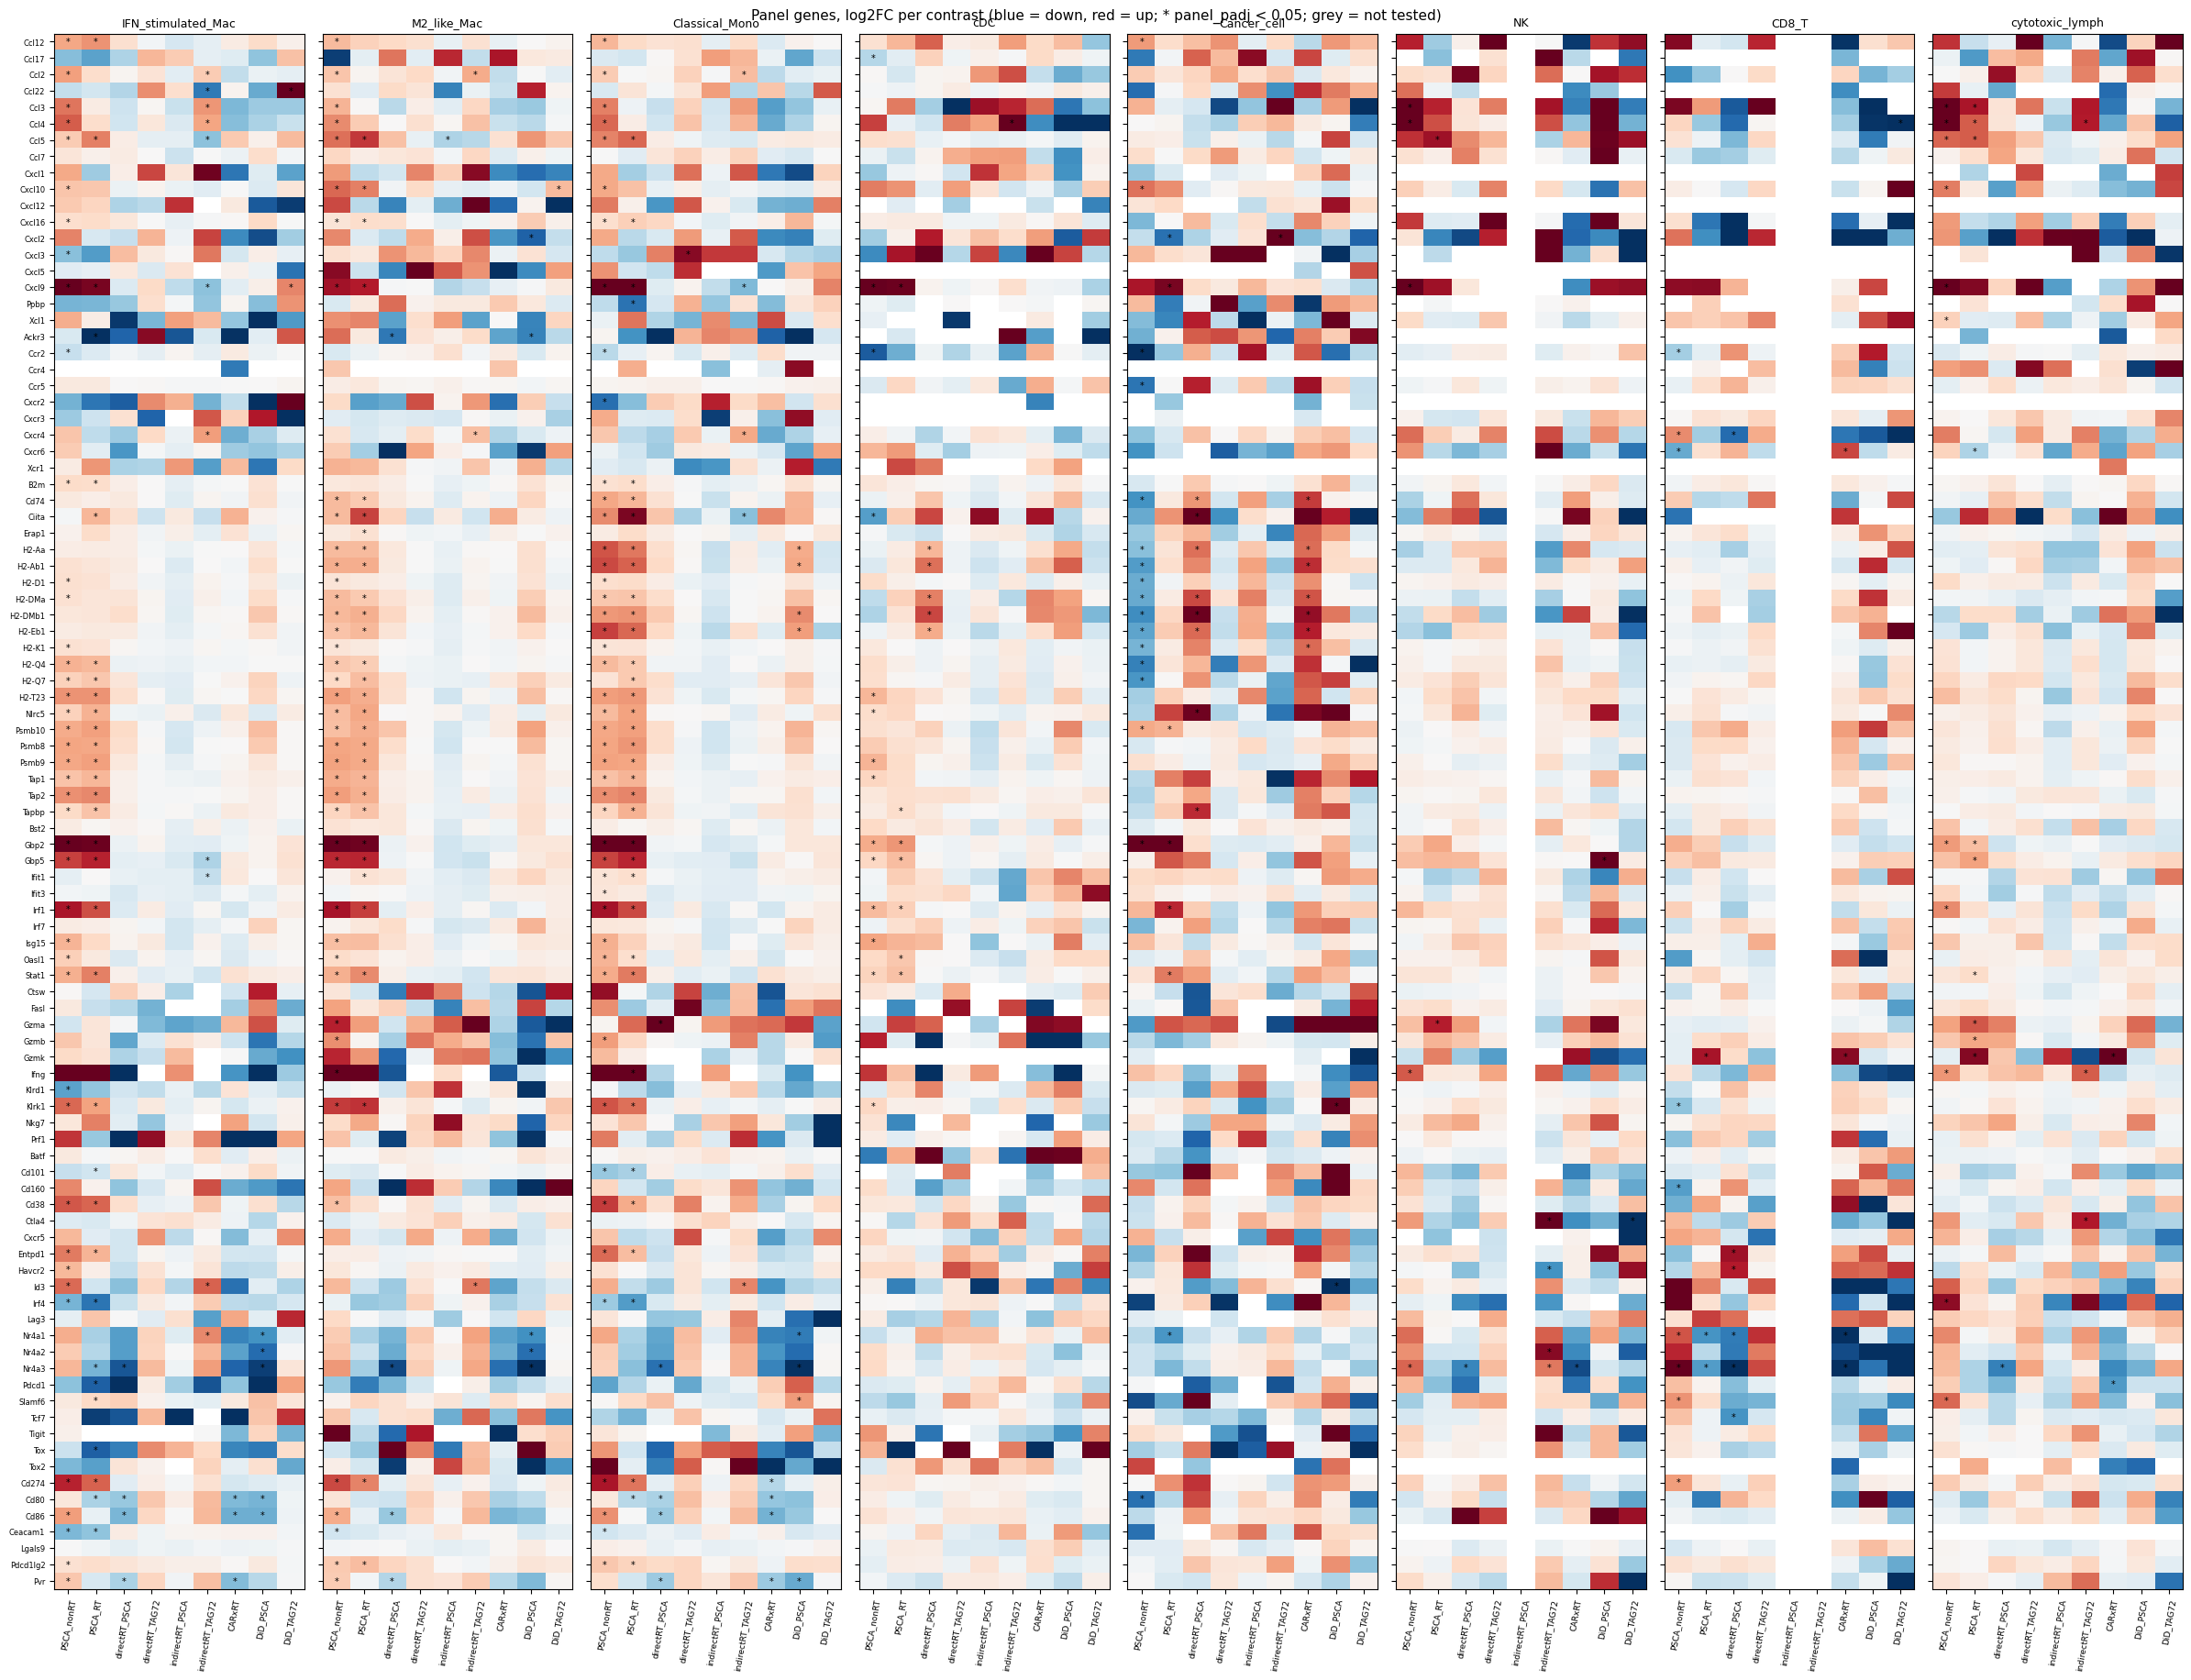

In [6]:
KEY_GROUPS = ["IFN_stimulated_Mac", "M2_like_Mac", "Classical_Mono", "cDC", "Cancer_cell", "NK",
              "CD8_T", "cytotoxic_lymph"]
order = (PANELS["chemokine_ligand"] + PANELS["chemokine_receptor"] + PANELS["MHC"] + PANELS["IFN"]
         + PANELS["cytotoxic"] + PANELS["exhaustion"] + PANELS["checkpoint"])
order = list(dict.fromkeys(order))
fig, axes = plt.subplots(1, len(KEY_GROUPS), figsize=(3.0*len(KEY_GROUPS), 0.17*len(order) + 2.5),
                         sharey=True)
for ax, g_ in zip(axes, KEY_GROUPS):
    d = P[(P.group == g_) & P.contrast.isin(CMAIN)]
    F = d.pivot_table(index="gene", columns="contrast", values="log2FoldChange").reindex(index=order, columns=CMAIN)
    Q = d.pivot_table(index="gene", columns="contrast", values="panel_padj").reindex(index=order, columns=CMAIN)
    ax.imshow(F.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -3, 3), aspect="auto")
    for i in range(F.shape[0]):
        for j in range(F.shape[1]):
            if pd.notna(Q.values[i, j]) and Q.values[i, j] < 0.05:
                ax.text(j, i, "*", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(CMAIN))); ax.set_xticklabels(CMAIN, rotation=80, fontsize=6.5)
    ax.set_title(g_, fontsize=9)
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order, fontsize=6)
fig.suptitle("Panel genes, log2FC per contrast (blue = down, red = up; * panel_padj < 0.05; grey = not tested)",
             fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"02_panel_heatmaps.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Summary

In [7]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
ok = LOG[LOG.status == "ok"]
print(f"\n[fits] {len(ok)}/{len(LOG)} cell group x contrast fits succeeded; not fittable: "
      f"{LOG[LOG.status != 'ok'].groupby('group').contrast.count().to_dict()}")
print("\n[genome-wide padj<0.05, summed over the cell groups]")
print("   ", LOG.groupby("contrast").n_padj05.sum().reindex(list(CONTRASTS)).astype("Int64").to_dict())
for name in REP:
    d = R[(R.effect == name) & R.replicated]
    print(f"\n[{name}] replicated panel genes: {len(d)}")
    for pn, dd in d.groupby("panel"):
        items = [f"{r.gene}@{r.group}({r.lfc_1:+.1f}/{r.lfc_2:+.1f})" for _, r in dd.iterrows()]
        print(f"    {pn:<19s} {', '.join(items[:14])}{' ...' if len(items) > 14 else ''}")
for cname in ["CARxRT", "DiD_PSCA", "DiD_TAG72"]:
    d = P[(P.contrast == cname) & (P.panel_padj < 0.05)]
    print(f"[{cname}] panel genes at panel_padj<0.05: "
          f"{[f'{r.gene}@{r.group}({r.log2FoldChange:+.1f})' for _, r in d.iterrows()][:15]}")
print(f"\n[files] {OUT}: de_all.parquet, de_fit_log.csv, de_panel_genes.csv, de_panel_replication.csv")
print(f"[figure] {FIG/'02_panel_heatmaps.png'}")
print("=" * 100)

SUMMARY — report these back

[fits] 128/150 cell group x contrast fits succeeded; not fittable: {'CD8_T': 3, 'Endothelial': 6, 'Fibroblast': 8, 'N2_like_Neu': 3, 'NK': 2}

[genome-wide padj<0.05, summed over the cell groups]
    {'PSCA_nonRT': 6383, 'PSCA_RT': 2851, 'directRT_PSCA': 165, 'directRT_TAG72': 7, 'indirectRT_PSCA': 4, 'indirectRT_TAG72': 65, 'CARxRT': 42, 'DiD_PSCA': 34, 'DiD_TAG72': 2, 'TxNoTx': 18627}

[PSCA] replicated panel genes: 227
    IFN                 Gbp2@Cancer_cell(+3.8/+4.1), Irf1@Cancer_cell(+1.0/+2.3), Gbp2@Classical_Mono(+3.2/+3.1), Gbp5@Classical_Mono(+2.0/+2.3), Ifit1@Classical_Mono(+0.4/+0.5), Irf1@Classical_Mono(+2.5/+2.0), Oasl1@Classical_Mono(+1.0/+0.5), Stat1@Classical_Mono(+1.1/+1.6), Gbp2@Endothelial(+2.7/+3.7), Gbp5@Endothelial(+1.4/+4.0), Stat1@Endothelial(+1.5/+1.5), Gbp2@IFN_stimulated_Mac(+3.1/+3.0), Gbp5@IFN_stimulated_Mac(+2.0/+2.3), Irf1@IFN_stimulated_Mac(+2.4/+1.9) ...
    MHC                 Psmb10@Cancer_cell(+1.1/+1.0), B2m@Classical_